# CSE558 Assignment: Question 1 - JL for k-means clustering
Group: 2023543, 2023605  
Collaborators / URLs used: *(Used LLM's ( claude and chatgpt ) for understading and debugging the code and concept)*

In [2]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_kddcup99
from sklearn.cluster import KMeans

SEED = 558                      # every random number below derives from this seed
os.makedirs("figs", exist_ok=True)
os.makedirs("tables", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## Data matrix D

In [3]:
kdd = fetch_kddcup99(subset=None, as_frame=True)   # default 10% version
X = kdd.data

# (i) one-hot the 3 text features, convert the other 38 to float
cat_cols = ["protocol_type", "service", "flag"]
def _dec(v):
    return v.decode() if isinstance(v, (bytes, bytearray)) else str(v)
cat = pd.DataFrame({c: X[c].map(_dec) for c in cat_cols})
onehot = pd.get_dummies(cat, dtype=np.float32)
num = X.drop(columns=cat_cols).astype(float).astype(np.float32)
M = pd.concat([num.reset_index(drop=True), onehot.reset_index(drop=True)], axis=1)

# (ii) drop constant columns, (iii) min-max rescale to [0, 1]
Mv = M.to_numpy(dtype=np.float32)
mn, mx = Mv.min(0), Mv.max(0)
keep = mx > mn
print("constant columns dropped:", list(M.columns[~keep]))
D = ((Mv[:, keep] - mn[keep]) / (mx[keep] - mn[keep])).astype(np.float32)
del Mv, M, num, onehot, cat

n, d = D.shape
print(f"n = {n}, d = {d}")
assert D.min() >= 0 and D.max() <= 1

constant columns dropped: ['num_outbound_cmds', 'is_host_login']
n = 494021, d = 116


## Helpers

In [4]:
K = 15
def km_fit(Z, seed=SEED):
    return KMeans(n_clusters=K, n_init=5, random_state=seed).fit(Z)

def cost(D, B, chunk=50_000):
    """cost(D,B) = sum_i min_{b in B} ||D_i - b||^2, computed from the definition (chunked, float64)."""
    B = np.asarray(B, dtype=np.float64)
    b2 = (B ** 2).sum(1)
    tot = 0.0
    for s in range(0, len(D), chunk):
        Xc = D[s:s + chunk].astype(np.float64)
        d2 = (Xc ** 2).sum(1)[:, None] - 2 * Xc @ B.T + b2[None, :]
        tot += np.maximum(d2.min(1), 0).sum()
    return tot

def centres_from_labels(D, lab):
    """b_hat_j = mean of the ORIGINAL rows of D in cluster j."""
    return np.vstack([D[lab == j].astype(np.float64).mean(0) for j in range(K)])

def cost_partition(X, idx_list):
    """cost_X(C): sum of squared distances to the cluster means of X."""
    tot = 0.0
    for idx in idx_list:
        Xj = X[idx].astype(np.float64)
        tot += ((Xj - Xj.mean(0)) ** 2).sum()
    return tot

## (a) k-means on D

In [5]:
t0 = time.perf_counter()
kmD = km_fit(D)
time_D = time.perf_counter() - t0
B = kmD.cluster_centers_.astype(np.float64)
labD = kmD.labels_
cost_B = cost(D, B)
print(f"cost(D, B) = {cost_B:.6f}   (sklearn inertia_ = {kmD.inertia_:.6f})")
print(f"wall-clock time of k-means on D = {time_D:.2f} s")

cost(D, B) = 53621.647446   (sklearn inertia_ = 53595.558594)
wall-clock time of k-means on D = 88.03 s


## (b), (c), (d) Random projection of D, then k-means on E = D A^T
Each `(m, repetition)` uses a fresh Gaussian `A` with N(0, 1/m) entries (own numpy generator, not sklearn.random_projection). The time in (d) covers computing E plus k-means on E only.

In [13]:
MS = [5, 10, 15, 20, 25]
REPS = 5
rows = []
for m in MS:
    for r in range(REPS):
        rng = np.random.default_rng([SEED, 1, m, r])
        A = rng.normal(0.0, 1.0 / np.sqrt(m), size=(m, d))        # m x d
        t0 = time.perf_counter()
        E = D @ A.T.astype(np.float32)                             # n x m
        kmE = km_fit(E, seed=SEED + r)
        t_run = time.perf_counter() - t0
        # (b) centres in R^d: average original rows of D in each cluster found on E
        Bhat = centres_from_labels(D, kmE.labels_)
        # (c) centres mapped back with the pseudo-inverse: A^+ a
        Aplus = np.linalg.pinv(A)                                  # d x m
        Bplus = kmE.cluster_centers_.astype(np.float64) @ Aplus.T  # k x d
        c_hat, c_plus = cost(D, Bhat), cost(D, Bplus)
        rows.append(dict(m=m, rep=r, cost_hat=c_hat, ratio_hat=c_hat / cost_B,
                         cost_plus=c_plus, ratio_plus=c_plus / cost_B, time=t_run))
    print("done m =", m)
res1 = pd.DataFrame(rows)
res1.to_csv("tables/q1_runs.csv", index=False)
res1

done m = 5
done m = 10
done m = 15
done m = 20
done m = 25


,m,rep,cost_hat,ratio_hat,cost_plus,ratio_plus,time
0,5,0,65202.307872,1.215970,4.030487e+06,75.165294,5.725644
1,5,1,64226.319431,1.197768,4.293886e+06,80.077480,4.726360
2,5,2,65046.660658,1.213067,4.320677e+06,80.577105,5.028798
3,5,3,62452.559478,1.164689,4.344703e+06,81.025163,5.001804
4,5,4,59359.259118,1.107002,4.364159e+06,81.388011,4.586355
5,10,0,65572.609822,1.222876,4.133016e+06,77.077376,6.217751
6,10,1,55591.678739,1.036739,4.023154e+06,75.028544,5.062003
7,10,2,58129.401546,1.084066,4.041278e+06,75.366534,7.309028
8,10,3,61288.947884,1.142989,4.127897e+06,76.981920,6.680318
9,10,4,59345.387846,1.106743,4.018319e+06,74.938376,4.829369


In [14]:
summ = res1.groupby("m").agg(
    ratio_hat_mean=("ratio_hat", "mean"), ratio_hat_min=("ratio_hat", "min"), ratio_hat_max=("ratio_hat", "max"),
    ratio_plus_mean=("ratio_plus", "mean"), ratio_plus_min=("ratio_plus", "min"), ratio_plus_max=("ratio_plus", "max"),
    time_mean=("time", "mean"))
summ.to_csv("tables/q1_summary.csv")
print("cost(D,B) =", cost_B, "| time on D =", round(time_D, 2), "s")
summ.round(4)

cost(D,B) = 53621.647446312985 | time on D = 88.03 s


,ratio_hat_mean,ratio_hat_min,ratio_hat_max,ratio_plus_mean,ratio_plus_min,ratio_plus_max,time_mean
m,,,,,,,
5,1.1797,1.1070,1.2160,79.6466,75.1653,81.3880,5.0138
10,1.1187,1.0367,1.2229,75.8785,74.9384,77.0774,6.0197
15,1.0562,0.9668,1.1851,71.0191,68.3549,72.8411,8.6884
20,0.9968,0.9722,1.0316,68.5984,64.9207,71.4541,9.3424
25,1.0361,1.0041,1.0766,62.9250,59.6917,66.3904,10.4100


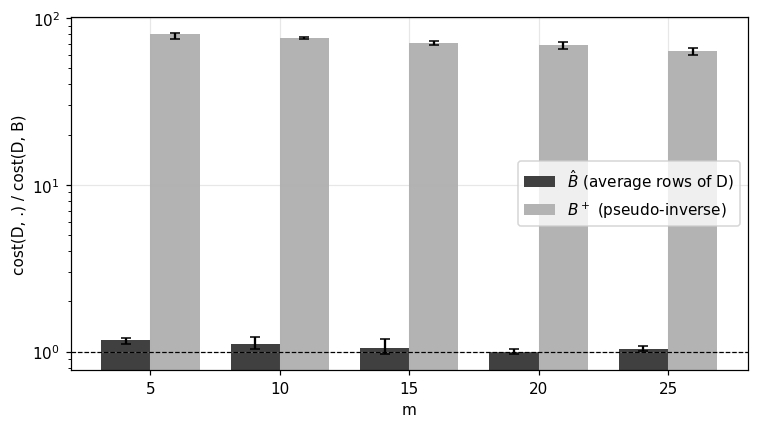

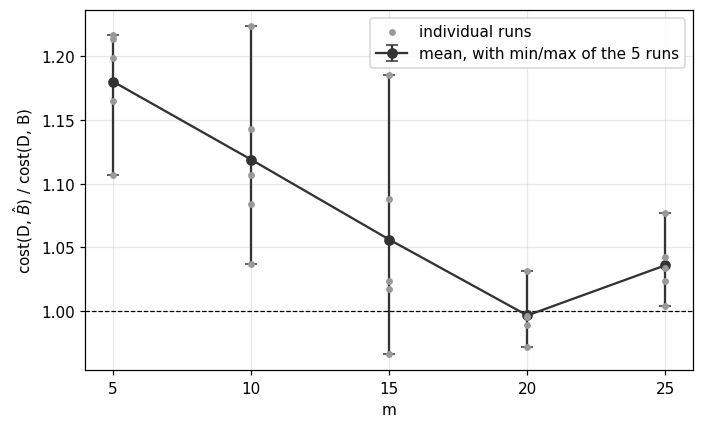

In [15]:
# (b)+(c) bar graph: mean ratio with min/max whiskers, B_hat vs B_plus (log y because B_plus can be huge)
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(MS)); w = 0.38
for off, nm, col in [(-w/2, "hat", "0.25"), (w/2, "plus", "0.70")]:
    mean = summ[f"ratio_{nm}_mean"].values
    lo, hi = summ[f"ratio_{nm}_min"].values, summ[f"ratio_{nm}_max"].values
    ax.bar(x + off, mean, w, yerr=[mean - lo, hi - mean], capsize=3, color=col,
           label=r"$\hat B$ (average rows of D)" if nm == "hat" else r"$B^+$ (pseudo-inverse)")
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xticks(x); ax.set_xticklabels(MS); ax.set_yscale("log")
ax.set_xlabel("m"); ax.set_ylabel("cost(D, .) / cost(D, B)"); ax.legend()
plt.tight_layout(); plt.savefig("figs/q1_bc_ratio.png"); plt.show()

# B_hat alone on a linear axis, so the trend in m is readable (B_plus is ~70x larger and squashes it above)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.errorbar(summ.index, summ["ratio_hat_mean"],
            yerr=[summ["ratio_hat_mean"] - summ["ratio_hat_min"], summ["ratio_hat_max"] - summ["ratio_hat_mean"]],
            fmt="o-", color="0.2", capsize=4, label="mean, with min/max of the 5 runs")
ax.scatter(res1["m"], res1["ratio_hat"], s=12, color="0.6", zorder=3, label="individual runs")
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xticks(MS); ax.set_xlabel("m"); ax.set_ylabel(r"cost(D, $\hat B$) / cost(D, B)"); ax.legend()
plt.tight_layout(); plt.savefig("figs/q1_b_ratio_hat_only.png"); plt.show()



### Comments for (b)

**How the ratio changes with m.** With m = 5 the clustering we get from the projected data is about 18% more expensive than the one from the full data (mean ratio 1.18). It gets better as m grows: 1.12 at m = 10, 1.06 at m = 15 and about 1.00 at m = 20. At m = 25 the mean is 1.04, a bit higher than at m = 20, but we don't read that as a real trend. With only 5 runs per m the min-max ranges overlap (0.97-1.03 at m = 20 and 1.00-1.08 at m = 25), so it is most likely noise from k-means ending up in different local optima. The overall picture is what JL predicts: a bigger m keeps the distances better, so the clusters found on E look more like the clusters on D, and the ratio and its min-max spread both shrink. Even m = 5 (against d = 116) is only about 20% off.

**Ratios below 1.** Five of the 25 runs gave a ratio below 1: one at m = 15 (0.967) and four at m = 20 (0.972 to 0.996). That is not a contradiction. k-means only finds a local minimum, so the B from (a) is not the true optimum. A run on the projected data can land in a better local minimum, and since we recompute the centres as the average of the original rows, its cost on D can come out slightly lower. So a ratio below 1 says the baseline run was not optimal, not that projection beats the optimum.

### Comments for (c)

B+ is far worse than B-hat. Its cost is roughly 60-80 times the baseline cost at every m (mean ratio 79.6 at m = 5, down to 62.9 at m = 25), while B-hat stays around 1.0-1.2. It improves slowly with m but never gets close. The reason is simple: the centres found on E are a_j = A mu_j, where mu_j is the true cluster mean, so A+ a_j = A+ A mu_j, which is just the projection of mu_j onto the m-dimensional row space of A. Everything outside that subspace is thrown away, and since our data lives in [0,1] with centres far from 0, that puts the centres in the wrong place. B-hat avoids the problem by keeping the cluster assignments from E and averaging the original rows, so it is the real mean of each cluster in R^d. We would use B-hat.


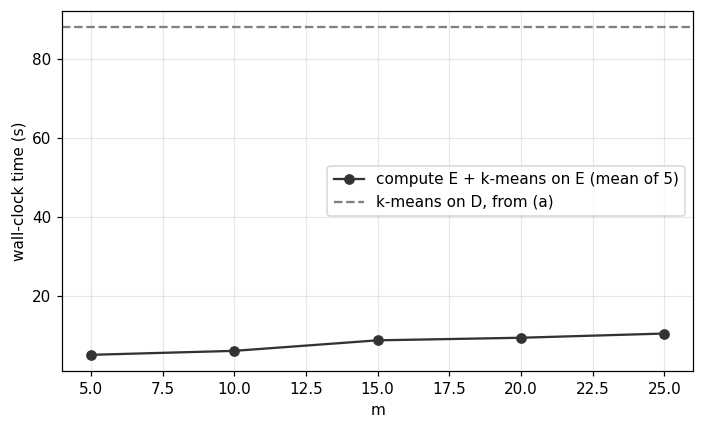

,time_mean
m,
5,5.014
10,6.020
15,8.688
20,9.342
25,10.410


In [16]:
# (d) running time vs m, horizontal line = time of k-means on D from (a)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(summ.index, summ["time_mean"], "o-", color="0.2", label="compute E + k-means on E (mean of 5)")
ax.axhline(time_D, color="0.5", ls="--", label="k-means on D, from (a)")
ax.set_xlabel("m"); ax.set_ylabel("wall-clock time (s)"); ax.legend()
plt.tight_layout(); plt.savefig("figs/q1_d_time.png"); plt.show()
summ[["time_mean"]].round(3)

### Comment for (d)

K-means on the projected data is significantly faster than on the original data. The original K-means took **88.03 seconds**, whereas the average times for m = 5, 10, 15, 20, and 25 were **5.01, 6.02, 8.69, 9.34, and 10.41 seconds**, respectively.

This represents a speedup of approximately **8.5–17.6 times**. The runtime generally increases with the projection dimension because K-means operates on more features.

Overall, random projection substantially reduces computation time while maintaining reasonably good clustering quality.

## (e) Distance distortion vs. cost distortion
(i) 10^4 random pairs with D_i != D_l (same pairs for all m), one draw of A per m.  
(ii) 20 independent draws of A per m: cost_E(C_D) / cost_D(C_D) with the clusters C_D from (a).

In [10]:
rngp = np.random.default_rng([SEED, 2])
NP = 10_000
I, L = [], []
while sum(len(a) for a in I) < NP:
    i = rngp.integers(0, n, 20_000); l = rngp.integers(0, n, 20_000)
    ok = (D[i] != D[l]).any(axis=1)                # excludes i == l and duplicate rows
    I.append(i[ok]); L.append(l[ok])
I = np.concatenate(I)[:NP]; L = np.concatenate(L)[:NP]
DI, DL = D[I].astype(np.float64), D[L].astype(np.float64)
dist_D = ((DI - DL) ** 2).sum(1)
assert (dist_D > 0).all()

idx_list = [np.where(labD == j)[0] for j in range(K)]
cost_D_CD = cost_partition(D, idx_list)
print("cost_D(C_D) =", cost_D_CD, "(should be ~ cost(D,B) =", cost_B, ")")

pair_ratios, cost_ratios = {}, {}
for m in MS:
    rng = np.random.default_rng([SEED, 3, m])
    A = rng.normal(0.0, 1.0 / np.sqrt(m), size=(m, d))
    dist_E = (((DI - DL) @ A.T) ** 2).sum(1)       # ||A(D_i - D_l)||^2
    pair_ratios[m] = dist_E / dist_D
    cr = []
    for t in range(20):
        rng = np.random.default_rng([SEED, 4, m, t])
        A = rng.normal(0.0, 1.0 / np.sqrt(m), size=(m, d))
        E = D @ A.T.astype(np.float32)
        cr.append(cost_partition(E, idx_list) / cost_D_CD)
    cost_ratios[m] = np.array(cr)
    print("done m =", m)

cost_D(C_D) = 53618.775887435324 (should be ~ cost(D,B) = 53621.647446312985 )
done m = 5
done m = 10
done m = 15
done m = 20
done m = 25


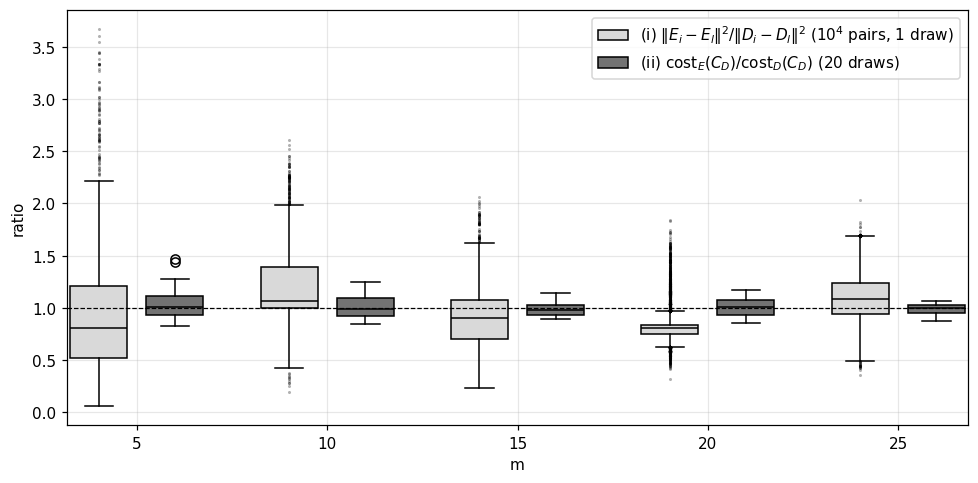

,(i) std,(i) IQR,(ii) std,(ii) IQR,(i) median,(ii) median
m,,,,,,
5,0.4296,0.6920,0.1758,0.1837,0.8016,1.0096
10,0.2879,0.3971,0.1150,0.1702,1.0659,0.9904
15,0.2385,0.3695,0.0732,0.0944,0.8974,0.9813
20,0.1617,0.0851,0.0904,0.1461,0.8040,1.0042
25,0.2254,0.3010,0.0484,0.0750,1.0838,0.9943


In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
pos = np.arange(len(MS)) * 3.0
b1 = ax.boxplot([pair_ratios[m] for m in MS], positions=pos - 0.6, widths=0.9, patch_artist=True, showfliers=True,
                 flierprops=dict(marker=".", markersize=2, alpha=0.3))
b2 = ax.boxplot([cost_ratios[m] for m in MS], positions=pos + 0.6, widths=0.9, patch_artist=True, showfliers=True)
for bp, col in [(b1, "0.85"), (b2, "0.45")]:
    for p in bp["boxes"]: p.set_facecolor(col)
    for med in bp["medians"]: med.set_color("k")
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xticks(pos); ax.set_xticklabels(MS); ax.set_xlabel("m"); ax.set_ylabel("ratio")
ax.legend([b1["boxes"][0], b2["boxes"][0]],
          [r"(i) $\|E_i-E_l\|^2/\|D_i-D_l\|^2$ (10$^4$ pairs, 1 draw)", r"(ii) cost$_E(C_D)$/cost$_D(C_D)$ (20 draws)"])
plt.tight_layout(); plt.savefig("figs/q1_e_boxplots.png"); plt.show()

spread = pd.DataFrame({
    "(i) std": [pair_ratios[m].std() for m in MS],
    "(i) IQR": [np.subtract(*np.percentile(pair_ratios[m], [75, 25])) for m in MS],
    "(ii) std": [cost_ratios[m].std() for m in MS],
    "(ii) IQR": [np.subtract(*np.percentile(cost_ratios[m], [75, 25])) for m in MS],
    "(i) median": [np.median(pair_ratios[m]) for m in MS],
    "(ii) median": [np.median(cost_ratios[m]) for m in MS]}, index=MS)
spread.index.name = "m"
spread.to_csv("tables/q1_e_spread.csv")
spread.round(4)

**Extra check for (e)(i).** The spec uses *one* draw of A, and all 10^4 pairs share it, so the whole box can shift away from 1 because of that one draw. Here we repeat (i) with 20 different draws of A per m and look only at the median pair ratio of each draw.

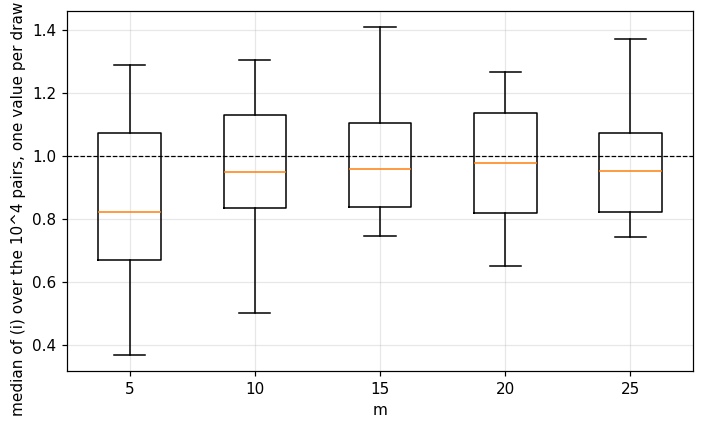

,mean of medians,std of medians
m,,
5,0.8472,0.2724
10,0.9583,0.2122
15,0.9957,0.1914
20,0.9708,0.1797
25,0.9799,0.1694


In [12]:
med_draws = {}
for m in MS:
    meds = []
    for t in range(20):
        rng = np.random.default_rng([SEED, 5, m, t])
        A = rng.normal(0.0, 1.0 / np.sqrt(m), size=(m, d))
        meds.append(np.median((((DI - DL) @ A.T) ** 2).sum(1) / dist_D))
    med_draws[m] = np.array(meds)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.boxplot([med_draws[m] for m in MS], positions=np.arange(len(MS)), widths=0.5)
ax.set_xticks(np.arange(len(MS))); ax.set_xticklabels(MS)
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xlabel("m"); ax.set_ylabel("median of (i) over the 10^4 pairs, one value per draw of A")
plt.tight_layout(); plt.savefig("figs/q1_e_median_over_draws.png"); plt.show()
pd.DataFrame({"mean of medians": [med_draws[m].mean() for m in MS],
              "std of medians": [med_draws[m].std() for m in MS]}, index=MS).rename_axis("m").round(4)


### Comments for (e)

**Which has the smaller spread?** In terms of standard deviation, (ii), the cost ratio over 20 draws, is smaller than (i), the pair distances from one draw, at every m: (i) has 0.43, 0.29, 0.24, 0.16, 0.23 and (ii) has 0.18, 0.12, 0.07, 0.09, 0.05 for m = 5, 10, 15, 20, 25. On the box plot, (ii) is also visibly tighter at m = 5, 10, 15 and 25. m = 20 is the one place where the (i) box looks narrower than (ii). But that box sits around 0.8 rather than 1 and has long tails, so it is narrow and in the wrong place, and its standard deviation is still larger than that of (ii).

**Why.** (i) is the distortion of one squared distance, which behaves like a scaled chi-square variable with variance of order 2/m, so even at m = 25 individual pairs are easily off by 25% or more. (ii) is a sum over all n points, so much of that noise averages out, and it stays centred at 1 (medians 0.98-1.01).

**How each changes with m.** Both get tighter as m grows, roughly like 1/sqrt(m) (for (ii) the std goes 0.18 down to 0.05), but neither is perfectly monotone. (ii) has a bump at m = 20, which is not surprising with only 20 draws per m. For (i), all 10^4 pairs use the same A, so the pairs are not independent and the whole box can shift with the luck of that one draw, because differences between rows are dominated by a few features. That is why its medians (0.80, 1.07, 0.90, 0.80, 1.08) wander around 1 instead of sitting on it. It is a property of using a single draw and not a bug; the extra check above repeats (i) over 20 draws per m to show that the median moves around from draw to draw.
